In [1]:
import sys
import os

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from models.model_utils import orthonormalize_qr

In [2]:
rng = np.random.default_rng(2)

# --- Generate non-Gaussian 2D data: a "ring + arm" shape ---
n_ring = 700
angles = rng.uniform(0, 2*np.pi, size=n_ring)
r = 2.0 + 0.15 * rng.normal(size=n_ring)          # thin noisy ring
ring = np.c_[r * np.cos(angles), r * np.sin(angles)]

n_arm = 500
t = rng.uniform(-2.5, 2.5, size=n_arm)
arm = np.c_[t, 0.25 * rng.normal(size=n_arm)]     # thin horizontal arm
arm[:, 1] += 1.2                                  # shift it upward

X = np.vstack([ring, arm])
X = np.vstack([X, [
	X[0] * 2
]])




# --- Build a transform: shear + scale + rotation ---
theta = np.deg2rad(35)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])

sx, sy = 1.4, 0.75
S = np.array([[sx, 0.0],
              [0.0, sy]])

k = 1.1  # x-shear
H = np.array([[1.0, k],
              [0.0, 1.0]])

A = R @ S @ H

In [3]:
def orthonormalize_qr(A):
	Q, R = np.linalg.qr(A)
	return Q * np.diag(R)  # also fixes sign ambiguity for a deterministic mapping


def orthonormalize_qr(A):
	Q, R = np.linalg.qr(A)
	signs = np.sign(np.diag(R))  # fix sign ambiguity for a deterministic mapping
	return Q * np.where(signs == 0, 1.0, signs)


def shear_qr(A):
	Q, R = np.linalg.qr(A)
	return R

Combined transform A = R @ S @ H:
 [[1.14681286 0.83131182]
 [0.80300701 1.49767175]]


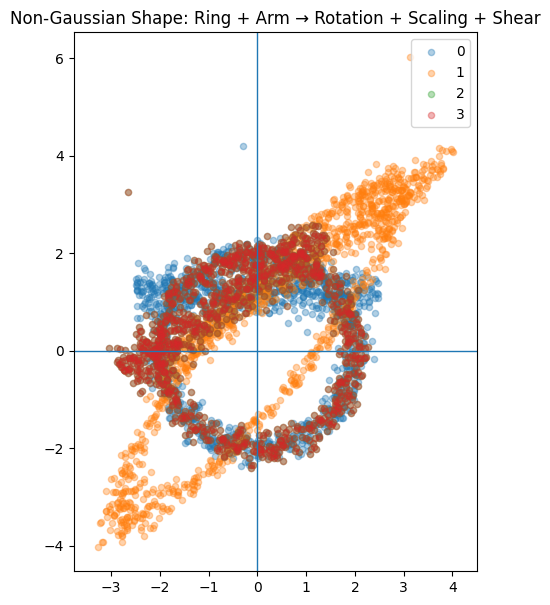

In [4]:
# Apply to row-vectors: y = x A^T
Y = X @ A.T
Y_orm = X @ orthonormalize_qr(A).T
Y_orth = X @ orthonormalize_qr(A).T

print("Combined transform A = R @ S @ H:\n", A)


all_pts = np.vstack([X, Y])
pad = 0.5
xmin, ymin = all_pts.min(axis=0) - pad
xmax, ymax = all_pts.max(axis=0) + pad

fig, ax = plt.subplots(figsize=(7, 7))
ax.axhline(0, linewidth=1)
ax.axvline(0, linewidth=1)
ax.set_aspect("equal", "box")
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_title("Non-Gaussian Shape: Ring + Arm → Rotation + Scaling + Shear")

_all = [X, Y, Y_orth, Y_orm]
_trans = [Y, Y_orth]
_withshear = [Y, shear_qr(A)]
for i, M in enumerate(_all):
	ax.scatter(M[:, 0], M[:, 1], s=20, alpha=0.35, label=f'{i}')

ax.legend()